In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)


In [2]:

ashok_vihar = pd.read_csv("AshokVihar_Hourly.csv")
print(ashok_vihar)


       Unnamed: 0  PM2.5    year  month  day  hour    PM10     AT      BP  \
0               0  77.00  2018.0    6.0  1.0   0.0  274.00  34.51  975.17   
1               1  75.00  2018.0    6.0  1.0   1.0  237.00  34.05  976.08   
2               2  81.00  2018.0    6.0  1.0   2.0  219.00  33.12  991.25   
3               3  70.00  2018.0    6.0  1.0   3.0  217.00  32.54  998.50   
4               4  74.00  2018.0    6.0  1.0   4.0  226.00  31.93  997.90   
...           ...    ...     ...    ...  ...   ...     ...    ...     ...   
11700       11700  34.50  2019.0   10.0  1.0  12.0   98.25  34.00  985.33   
11701       11701  37.50  2019.0   10.0  1.0  13.0  111.75  33.95  984.17   
11702       11702  41.25  2019.0   10.0  1.0  14.0  125.75  31.18  983.45   
11703       11703  39.00  2019.0   10.0  1.0  15.0  132.25  31.55  983.00   
11704       11704  39.25  2019.0   10.0  1.0  16.0  125.75  29.95  982.90   

           SR  ...    WS      WD    NO    NO2    SO2   Ozone    CO  Benzene

In [3]:
DCStadium_Hourly = pd.read_csv("DCStadium_Hourly.csv")
print(DCStadium_Hourly)

       Unnamed: 0  PM2.5    year  month  day  hour    PM10     AT      BP  \
0               0  75.00  2018.0    6.0  1.0   0.0  221.00  33.82  979.00   
1               1  79.00  2018.0    6.0  1.0   1.0  185.00  33.43  979.00   
2               2  55.00  2018.0    6.0  1.0   2.0  173.00  32.51  979.00   
3               3  63.00  2018.0    6.0  1.0   3.0  195.00  31.92  979.00   
4               4  68.00  2018.0    6.0  1.0   4.0  217.00  31.19  979.00   
...           ...    ...     ...    ...  ...   ...     ...    ...     ...   
11699       11699  21.00  2019.0   10.0  1.0  11.0   64.00  31.05  987.60   
11700       11700  24.75  2019.0   10.0  1.0  12.0   64.00  32.42  986.70   
11701       11701  27.25  2019.0   10.0  1.0  13.0   66.75  31.85  985.60   
11702       11702  28.00  2019.0   10.0  1.0  14.0   75.75  31.52  984.65   
11703       11703  29.25  2019.0   10.0  1.0  15.0   80.50  30.45  984.17   

           SR  ...    WS      WD    NO    NO2    SO2  Ozone    CO  Benzene 

In [4]:
DwarkaSec8_Hourly = pd.read_csv("DwarkaSec8_Hourly.csv")
print(DwarkaSec8_Hourly)

       Unnamed: 0   PM2.5    year  month  day  hour    PM10     AT      BP  \
0               0   61.00  2018.0    6.0  1.0   0.0  284.00  34.77  976.00   
1               1   63.00  2018.0    6.0  1.0   1.0  262.00  34.40  976.00   
2               2   74.00  2018.0    6.0  1.0   2.0  218.00  33.48  976.00   
3               3   53.00  2018.0    6.0  1.0   3.0  208.00  32.57  976.00   
4               4  117.00  2018.0    6.0  1.0   4.0  241.00  32.07  976.08   
...           ...     ...     ...    ...  ...   ...     ...    ...     ...   
11699       11699   46.00  2019.0   10.0  1.0  11.0  222.75  31.85  983.95   
11700       11700   52.00  2019.0   10.0  1.0  12.0  240.50  32.50  983.07   
11701       11701   51.00  2019.0   10.0  1.0  13.0  280.50  32.57  981.90   
11702       11702   44.75  2019.0   10.0  1.0  14.0  318.50  30.55  981.30   
11703       11703   35.00  2019.0   10.0  1.0  15.0  248.00  31.40  980.60   

           SR  ...    WS      WD      NO     NO2   SO2      Ozo

In [5]:
Najafgarh_Hourly = pd.read_csv("Najafgarh_Hourly.csv")
print(Najafgarh_Hourly)

       Unnamed: 0  PM2.5    year  month  day  hour   PM10     AT      BP  \
0               0   58.0  2018.0    6.0  1.0   0.0  277.0  33.75  978.08   
1               1   64.0  2018.0    6.0  1.0   1.0  260.0  33.56  978.00   
2               2   52.0  2018.0    6.0  1.0   2.0  204.0  32.83  978.00   
3               3   55.0  2018.0    6.0  1.0   3.0  201.0  32.17  978.00   
4               4   61.0  2018.0    6.0  1.0   4.0  200.0  32.11  978.33   
...           ...    ...     ...    ...  ...   ...    ...    ...     ...   
11699       11699   18.0  2019.0   10.0  1.0  11.0   76.5  31.40  986.67   
11700       11700   17.0  2019.0   10.0  1.0  12.0   81.0  30.85  985.80   
11701       11701   26.5  2019.0   10.0  1.0  13.0   77.0  31.88  984.83   
11702       11702   33.5  2019.0   10.0  1.0  14.0   80.0  29.02  984.10   
11703       11703   31.5  2019.0   10.0  1.0  15.0   63.5  30.12  983.65   

           SR  ...    WS      WD    NO    NO2    SO2   Ozone    CO  Benzene  \
0       

In [6]:
NehruNagar_Hourly = pd.read_csv("NehruNagar_Hourly.csv")
print(NehruNagar_Hourly)

       Unnamed: 0  PM2.5    year  month  day  hour    PM10     AT      BP  \
0               0  72.50  2018.0    6.0  1.0   0.0  241.25  38.77  979.00   
1               1  70.00  2018.0    6.0  1.0   1.0  234.00  38.00  979.00   
2               2  52.00  2018.0    6.0  1.0   2.0  186.00  36.84  979.58   
3               3  57.00  2018.0    6.0  1.0   3.0  221.00  36.45  979.33   
4               4  57.00  2018.0    6.0  1.0   4.0  204.00  35.62  980.00   
...           ...    ...     ...    ...  ...   ...     ...    ...     ...   
11700       11700  32.75  2019.0   10.0  1.0  12.0   78.75  31.30  984.12   
11701       11701  28.50  2019.0   10.0  1.0  13.0   73.75  31.07  983.15   
11702       11702  27.25  2019.0   10.0  1.0  14.0   71.75  30.62  982.22   
11703       11703  26.50  2019.0   10.0  1.0  15.0   78.75  29.70  981.75   
11704       11704  22.00  2019.0   10.0  1.0  16.0   84.00  28.70  981.85   

           SR  ...    WS      WD    NO    NO2   SO2  Ozone    CO  Benzene  

In [7]:
Okhla_Hourly = pd.read_csv("Okhla_Hourly (1).csv")
print(Okhla_Hourly)

       Unnamed: 0  PM2.5    year  month  day  hour    PM10     AT      BP  \
0               0  70.00  2018.0    6.0  1.0   0.0  263.00  34.30  977.00   
1               1  73.00  2018.0    6.0  1.0   1.0  246.00  33.71  977.00   
2               2  68.00  2018.0    6.0  1.0   2.0  223.00  32.78  977.00   
3               3  64.00  2018.0    6.0  1.0   3.0  206.00  32.05  977.00   
4               4  73.00  2018.0    6.0  1.0   4.0  219.00  31.40  977.00   
...           ...    ...     ...    ...  ...   ...     ...    ...     ...   
11700       11700  29.00  2019.0   10.0  1.0  12.0   82.00  31.05  984.88   
11701       11701  26.75  2019.0   10.0  1.0  13.0   69.00  30.98  983.88   
11702       11702  20.50  2019.0   10.0  1.0  14.0   69.25  31.95  983.05   
11703       11703  24.75  2019.0   10.0  1.0  15.0   81.25  30.05  982.62   
11704       11704  33.00  2019.0   10.0  1.0  16.0   88.00  29.30  982.55   

           SR  ...    WS      WD    NO        NO2    SO2  Ozone    CO  \
0 

In [8]:


# List of Delhi air-quality CSV files
files = {

    "ashok_vihar": "AshokVihar_Hourly.csv",
    "DCStadium_Hourly": "DCStadium_Hourly.csv",
    "DwarkaSec8_Hourly": "DwarkaSec8_Hourly.csv",
    "Najafgarh_Hourly": "Najafgarh_Hourly.csv",
    "NehruNagar_Hourly": "NehruNagar_Hourly.csv",
    "Okhla_Hourly": "Okhla_Hourly (1).csv"
}

# Load and combine all datasets
dataframes = []

for station, file in files.items():
    temp_df = pd.read_csv(file)
    
    # Add station name
    temp_df["Station"] = station
    
    dataframes.append(temp_df)

# Combine all 6 datasets into one
delhi_air_quality = pd.concat(dataframes, ignore_index=True)

# Save the combined dataset
delhi_air_quality.to_csv(
    "Delhi_Combined_Air_Quality.csv",
    index=False
)

# Display basic information
print("Successfully combined all Delhi air-quality datasets!")
print("Final dataset shape:", delhi_air_quality.shape)
print("\nStations:")
print(delhi_air_quality["Station"].value_counts())

print("\nFirst 5 rows:")
display(delhi_air_quality.head())

Successfully combined all Delhi air-quality datasets!
Final dataset shape: (70227, 22)

Stations:
Station
ashok_vihar          11705
NehruNagar_Hourly    11705
Okhla_Hourly         11705
DCStadium_Hourly     11704
DwarkaSec8_Hourly    11704
Najafgarh_Hourly     11704
Name: count, dtype: int64

First 5 rows:


,Unnamed: 0,PM2.5,year,month,day,hour,PM10,AT,BP,SR,...,WD,NO,NO2,SO2,Ozone,CO,Benzene,NH3,NOx,Station
0,0,77.0,2018.0,6.0,1.0,0.0,274.0,34.51,975.17,2.00,...,129.0,3.21,23.36,10.93,98.13,0.53,5.14,43.00,26.55,ashok_vihar
1,1,75.0,2018.0,6.0,1.0,1.0,237.0,34.05,976.08,2.00,...,129.0,2.93,21.71,9.48,97.80,0.51,3.94,47.82,24.64,ashok_vihar
2,2,81.0,2018.0,6.0,1.0,2.0,219.0,33.12,991.25,2.00,...,129.0,2.27,11.90,1.68,46.27,0.12,4.55,10.64,15.24,ashok_vihar
3,3,70.0,2018.0,6.0,1.0,3.0,217.0,32.54,998.50,2.00,...,129.0,1.72,10.70,2.97,35.88,0.30,4.20,13.44,42.32,ashok_vihar
4,4,74.0,2018.0,6.0,1.0,4.0,226.0,31.93,997.90,2.08,...,129.0,1.83,32.49,2.73,26.55,0.39,3.32,8.48,44.78,ashok_vihar


In [9]:

# Copy the combined dataset
df = delhi_air_quality.copy()

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (70227, 22)

Column names:
['Unnamed: 0', 'PM2.5', 'year', 'month', 'day', 'hour', 'PM10', 'AT', 'BP', 'SR', 'RH', 'WS', 'WD', 'NO', 'NO2', 'SO2', 'Ozone', 'CO', 'Benzene', 'NH3', 'NOx', 'Station']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70227 entries, 0 to 70226
Data columns (total 22 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  70227 non-null  int64  
 1   PM2.5       70227 non-null  float64
 2   year        70227 non-null  float64
 3   month       70227 non-null  float64
 4   day         70227 non-null  float64
 5   hour        70227 non-null  float64
 6   PM10        70227 non-null  float64
 7   AT          70227 non-null  float64
 8   BP          70227 non-null  float64
 9   SR          70227 non-null  float64
 10  RH          70227 non-null  float64
 11  WS          70227 non-null  float64
 12  WD          70227 non-null  float64
 13  NO          70227 non-null  float64


In [10]:
df = delhi_air_quality.copy()

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (70227, 22)

Columns:
['Unnamed: 0', 'PM2.5', 'year', 'month', 'day', 'hour', 'PM10', 'AT', 'BP', 'SR', 'RH', 'WS', 'WD', 'NO', 'NO2', 'SO2', 'Ozone', 'CO', 'Benzene', 'NH3', 'NOx', 'Station']


In [11]:
print("Shape:", df.shape)

print("\nData types:")
df.info()

print("\nFirst 5 rows:")
display(df.head())

print("\nStatistical summary:")
display(df.describe())

Shape: (70227, 22)

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70227 entries, 0 to 70226
Data columns (total 22 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  70227 non-null  int64  
 1   PM2.5       70227 non-null  float64
 2   year        70227 non-null  float64
 3   month       70227 non-null  float64
 4   day         70227 non-null  float64
 5   hour        70227 non-null  float64
 6   PM10        70227 non-null  float64
 7   AT          70227 non-null  float64
 8   BP          70227 non-null  float64
 9   SR          70227 non-null  float64
 10  RH          70227 non-null  float64
 11  WS          70227 non-null  float64
 12  WD          70227 non-null  float64
 13  NO          70227 non-null  float64
 14  NO2         70227 non-null  float64
 15  SO2         70227 non-null  float64
 16  Ozone       70227 non-null  float64
 17  CO          70227 non-null  float64
 18  Benzene     70227 non-null  float6

,Unnamed: 0,PM2.5,year,month,day,hour,PM10,AT,BP,SR,...,WD,NO,NO2,SO2,Ozone,CO,Benzene,NH3,NOx,Station
0,0,77.0,2018.0,6.0,1.0,0.0,274.0,34.51,975.17,2.00,...,129.0,3.21,23.36,10.93,98.13,0.53,5.14,43.00,26.55,ashok_vihar
1,1,75.0,2018.0,6.0,1.0,1.0,237.0,34.05,976.08,2.00,...,129.0,2.93,21.71,9.48,97.80,0.51,3.94,47.82,24.64,ashok_vihar
2,2,81.0,2018.0,6.0,1.0,2.0,219.0,33.12,991.25,2.00,...,129.0,2.27,11.90,1.68,46.27,0.12,4.55,10.64,15.24,ashok_vihar
3,3,70.0,2018.0,6.0,1.0,3.0,217.0,32.54,998.50,2.00,...,129.0,1.72,10.70,2.97,35.88,0.30,4.20,13.44,42.32,ashok_vihar
4,4,74.0,2018.0,6.0,1.0,4.0,226.0,31.93,997.90,2.08,...,129.0,1.83,32.49,2.73,26.55,0.39,3.32,8.48,44.78,ashok_vihar



Statistical summary:


,Unnamed: 0,PM2.5,year,month,day,hour,PM10,AT,BP,SR,...,WS,WD,NO,NO2,SO2,Ozone,CO,Benzene,NH3,NOx
count,70227.000000,70227.000000,70227.000000,70227.000000,70227.000000,70227.000000,70227.000000,70227.000000,70227.000000,70227.000000,...,70227.000000,70227.000000,70227.000000,70227.000000,70227.000000,70227.000000,70227.000000,70227.000000,70227.000000,70227.000000
mean,5851.750011,92.926261,2018.561194,6.774574,15.708189,11.494724,211.558026,26.668836,982.613704,132.198788,...,1.371972,175.878477,32.601704,41.809682,14.964942,36.701293,1.382764,4.068596,32.958663,49.449357
std,3378.822176,97.943391,0.496245,3.065677,8.810151,6.921095,164.517213,8.322141,18.821209,192.644391,...,2.239880,86.522885,69.388835,30.633438,10.257380,42.632898,1.267207,4.973637,16.034952,67.713489
min,0.000000,0.030000,2018.000000,1.000000,1.000000,0.000000,0.830000,1.200000,702.500000,0.100000,...,0.100000,0.070000,0.100000,0.100000,0.100000,0.100000,0.000000,0.000000,0.100000,0.100000
25%,2926.000000,33.155661,2018.000000,5.000000,8.000000,5.000000,93.500000,20.950000,976.380000,4.103571,...,0.550000,103.650000,2.320000,19.850000,8.820000,5.620000,0.700000,1.100000,22.650000,14.270000
50%,5852.000000,58.000000,2019.000000,7.000000,16.000000,11.000000,168.500000,28.180000,982.500000,23.480000,...,0.930000,170.970000,6.030000,32.750000,12.550000,17.880000,1.000000,2.480000,29.880000,24.800000
75%,8778.000000,115.750000,2019.000000,9.000000,23.000000,17.000000,282.000000,32.420000,990.150000,202.990000,...,1.420000,251.070000,24.650000,55.030000,18.700000,54.250000,1.530000,4.950000,40.580000,51.570000
max,11704.000000,1000.000000,2019.000000,12.000000,31.000000,23.000000,1000.000000,48.200000,1094.250000,1000.380000,...,47.470000,357.350000,499.800000,323.600000,190.380000,199.900000,10.000000,83.500000,172.800000,500.000000


In [12]:
index_columns = [
    col for col in df.columns
    if col.lower().startswith("unnamed")
]

print("Index-like columns:", index_columns)

df = df.drop(columns=index_columns)

print("Shape after removing index columns:", df.shape)

Index-like columns: ['Unnamed: 0']
Shape after removing index columns: (70227, 21)


In [13]:
print("Duplicate rows before:",
      df.duplicated().sum())

Duplicate rows before: 0


In [14]:
df = df.drop_duplicates().reset_index(drop=True)

print("Duplicate rows after:",
      df.duplicated().sum())

print("New shape:", df.shape)

Duplicate rows after: 0
New shape: (70227, 21)


In [15]:
features = [
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "SO2",
    "CO",
    "O3",
    "NH3",
    "NOx"
]

# Keep only features that exist
features = [
    col for col in features
    if col in df.columns
]

print("Features selected for clustering:")
print(features)

Features selected for clustering:
['PM2.5', 'PM10', 'NO', 'NO2', 'SO2', 'CO', 'NH3', 'NOx']


In [16]:
for col in features:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

print(df[features].dtypes)

PM2.5    float64
PM10     float64
NO       float64
NO2      float64
SO2      float64
CO       float64
NH3      float64
NOx      float64
dtype: object


In [17]:
missing_values = df[features].isnull().sum()

print("Missing values:")
print(missing_values)

print("\nTotal missing values:",
      missing_values.sum())

Missing values:
PM2.5    0
PM10     0
NO       0
NO2      0
SO2      0
CO       0
NH3      0
NOx      0
dtype: int64

Total missing values: 0


In [18]:
print(
    "Infinite values:",
    np.isinf(df[features]).sum().sum()
)

Infinite values: 0


In [19]:
df[features] = df[features].replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Infinite values after replacement:",
    np.isinf(df[features]).sum().sum()
)

Infinite values after replacement: 0


In [20]:
negative_values = (df[features] < 0).sum()

print("Negative values:")
print(negative_values)

Negative values:
PM2.5    0
PM10     0
NO       0
NO2      0
SO2      0
CO       0
NH3      0
NOx      0
dtype: int64


In [21]:
for col in features:
    df.loc[df[col] < 0, col] = np.nan

print(
    "Total negative values after cleaning:",
    (df[features] < 0).sum().sum()
)

Total negative values after cleaning: 0


In [22]:
display(df[features].describe().T)

,count,mean,std,min,25%,50%,75%,max
PM2.5,70227.0,92.926261,97.943391,0.03,33.155661,58.00,115.75,1000.00
PM10,70227.0,211.558026,164.517213,0.83,93.500000,168.50,282.00,1000.00
NO,70227.0,32.601704,69.388835,0.10,2.320000,6.03,24.65,499.80
NO2,70227.0,41.809682,30.633438,0.10,19.850000,32.75,55.03,323.60
SO2,70227.0,14.964942,10.257380,0.10,8.820000,12.55,18.70,190.38
CO,70227.0,1.382764,1.267207,0.00,0.700000,1.00,1.53,10.00
NH3,70227.0,32.958663,16.034952,0.10,22.650000,29.88,40.58,172.80
NOx,70227.0,49.449357,67.713489,0.10,14.270000,24.80,51.57,500.00


In [24]:
skewness = df[features].skew().sort_values(
    ascending=False
)

print("Feature skewness:")
display(skewness)

Feature skewness:


NO       3.693109
NOx      3.308559
PM2.5    2.756269
CO       2.730357
SO2      2.727617
NO2      1.686984
PM10     1.668634
NH3      1.374841
dtype: float64

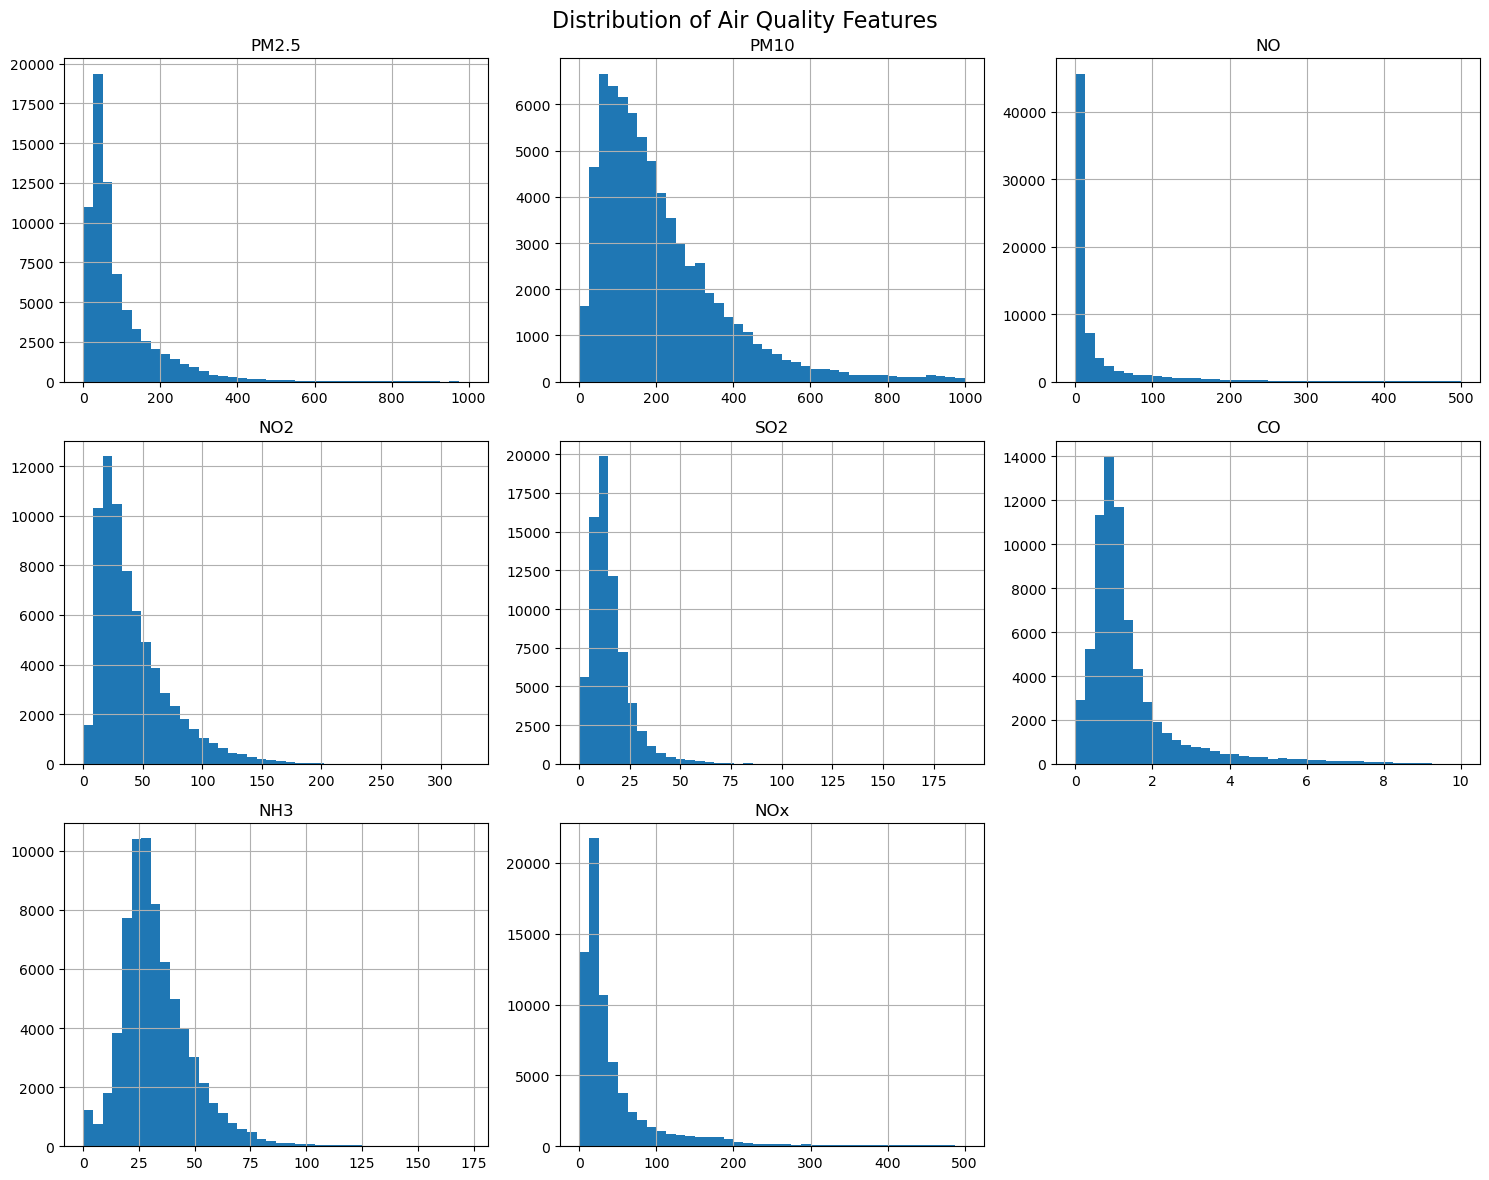

In [25]:
import matplotlib.pyplot as plt

df[features].hist(
    figsize=(15, 12),
    bins=40
)

plt.suptitle(
    "Distribution of Air Quality Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [26]:
for col in features:

    lower = df[col].quantile(0.001)
    upper = df[col].quantile(0.999)

    extreme_count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    print(
        f"{col}: "
        f"Lower={lower:.2f}, "
        f"Upper={upper:.2f}, "
        f"Extreme values={extreme_count}"
    )

PM2.5: Lower=1.00, Upper=801.25, Extreme values=127
PM10: Lower=4.00, Upper=977.09, Extreme values=135
NO: Lower=0.10, Upper=481.38, Extreme values=71
NO2: Lower=0.41, Upper=198.79, Extreme values=142
SO2: Lower=0.13, Upper=88.12, Extreme values=137
CO: Lower=0.00, Upper=8.90, Extreme values=67
NH3: Lower=0.34, Upper=124.31, Extreme values=139
NOx: Lower=1.00, Upper=481.65, Extreme values=139


In [27]:
skewed_features = []

for col in features:

    if (
        df[col].min() >= 0
        and abs(df[col].skew()) > 1
    ):
        df[col] = np.log1p(df[col])
        skewed_features.append(col)

print("Features transformed using log1p:")
print(skewed_features)

Features transformed using log1p:
['PM2.5', 'PM10', 'NO', 'NO2', 'SO2', 'CO', 'NH3', 'NOx']


In [28]:
skewness_after = df[features].skew().sort_values(
    ascending=False
)

print("Skewness after transformation:")
display(skewness_after)

Skewness after transformation:


CO       1.137176
NO       0.770680
NOx      0.626249
PM2.5   -0.033464
NO2     -0.331951
PM10    -0.534514
SO2     -0.603435
NH3     -1.483680
dtype: float64

In [29]:
correlation_matrix = df[features].corr()

display(correlation_matrix)

,PM2.5,PM10,NO,NO2,SO2,CO,NH3,NOx
PM2.5,1.000000,0.854459,0.500106,0.465388,0.316837,0.521803,0.413735,0.586271
PM10,0.854459,1.000000,0.424298,0.405655,0.295229,0.471398,0.294069,0.513540
NO,0.500106,0.424298,1.000000,0.564083,0.207012,0.701058,0.317262,0.870384
NO2,0.465388,0.405655,0.564083,1.000000,0.324153,0.478976,0.241330,0.806400
SO2,0.316837,0.295229,0.207012,0.324153,1.000000,0.210690,0.317888,0.233651
CO,0.521803,0.471398,0.701058,0.478976,0.210690,1.000000,0.371373,0.703604
NH3,0.413735,0.294069,0.317262,0.241330,0.317888,0.371373,1.000000,0.313832
NOx,0.586271,0.513540,0.870384,0.806400,0.233651,0.703604,0.313832,1.000000


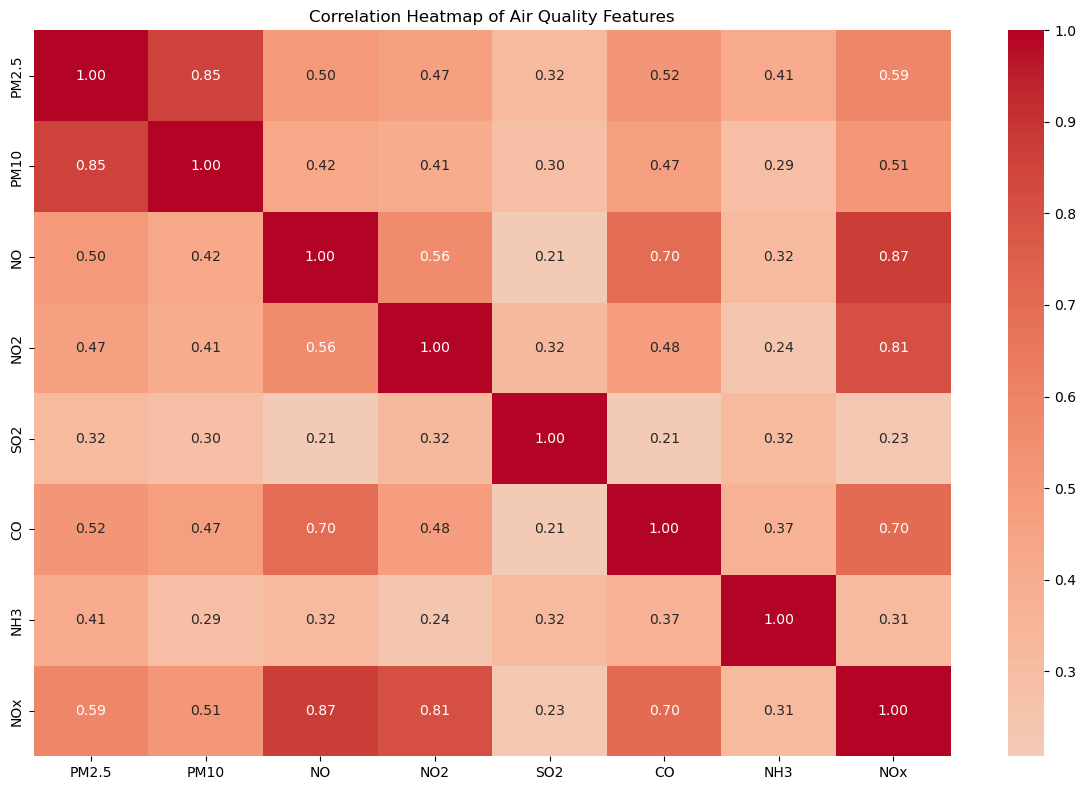

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Air Quality Features")
plt.tight_layout()
plt.show()

In [31]:
print("Highly correlated feature pairs:")

for i in range(len(features)):

    for j in range(i + 1, len(features)):

        correlation = correlation_matrix.iloc[i, j]

        if abs(correlation) > 0.90:

            print(
                features[i],
                "<-->",
                features[j],
                "=",
                round(correlation, 3)
            )

Highly correlated feature pairs:


In [34]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(
    strategy="median"
)

X_imputed = imputer.fit_transform(
    df[features]
)

print(
    "Missing values after imputation:",
    np.isnan(X_imputed).sum()
)

Missing values after imputation: 0


In [35]:
print("Shape of X_imputed:", X_imputed.shape)

print("Missing values:",
      np.isnan(X_imputed).sum())

print("Infinite values:",
      np.isinf(X_imputed).sum())

Shape of X_imputed: (70227, 8)
Missing values: 0
Infinite values: 0


In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_imputed)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (70227, 8)


In [37]:
print("Means after scaling:")
print(np.round(X_scaled.mean(axis=0), 3))

print("\nStandard deviations after scaling:")
print(np.round(X_scaled.std(axis=0), 3))

Means after scaling:
[-0.  0.  0.  0.  0. -0.  0. -0.]

Standard deviations after scaling:
[1. 1. 1. 1. 1. 1. 1. 1.]


In [38]:

print("=" * 60)
print("OUTLIER DETECTION USING IQR")
print("=" * 60)

outlier_summary = {}

for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    )

    outlier_count = outliers.sum()

    outlier_summary[col] = outlier_count

    print(f"\n{col}")
    print(f"Q1          : {Q1:.2f}")
    print(f"Q3          : {Q3:.2f}")
    print(f"IQR         : {IQR:.2f}")
    print(f"Lower bound : {lower_bound:.2f}")
    print(f"Upper bound : {upper_bound:.2f}")
    print(f"Outliers    : {outlier_count}")

print("\n" + "=" * 60)
print("OUTLIER SUMMARY")
print("=" * 60)

for col, count in outlier_summary.items():
    print(f"{col}: {count}")

OUTLIER DETECTION USING IQR

PM2.5
Q1          : 3.53
Q3          : 4.76
IQR         : 1.23
Lower bound : 1.69
Upper bound : 6.60
Outliers    : 526

PM10
Q1          : 4.55
Q3          : 5.65
IQR         : 1.10
Lower bound : 2.90
Upper bound : 7.29
Outliers    : 768

NO
Q1          : 1.20
Q3          : 3.24
IQR         : 2.04
Lower bound : -1.87
Upper bound : 6.31
Outliers    : 0

NO2
Q1          : 3.04
Q3          : 4.03
IQR         : 0.99
Lower bound : 1.55
Upper bound : 5.51
Outliers    : 600

SO2
Q1          : 2.28
Q3          : 2.98
IQR         : 0.70
Lower bound : 1.24
Upper bound : 4.02
Outliers    : 2868

CO
Q1          : 0.53
Q3          : 0.93
IQR         : 0.40
Lower bound : -0.07
Upper bound : 1.52
Outliers    : 4439

NH3
Q1          : 3.16
Q3          : 3.73
IQR         : 0.56
Lower bound : 2.32
Upper bound : 4.57
Outliers    : 2462

NOx
Q1          : 2.73
Q3          : 3.96
IQR         : 1.24
Lower bound : 0.87
Upper bound : 5.82
Outliers    : 1149

OUTLIER SUMMARY
PM2.5:

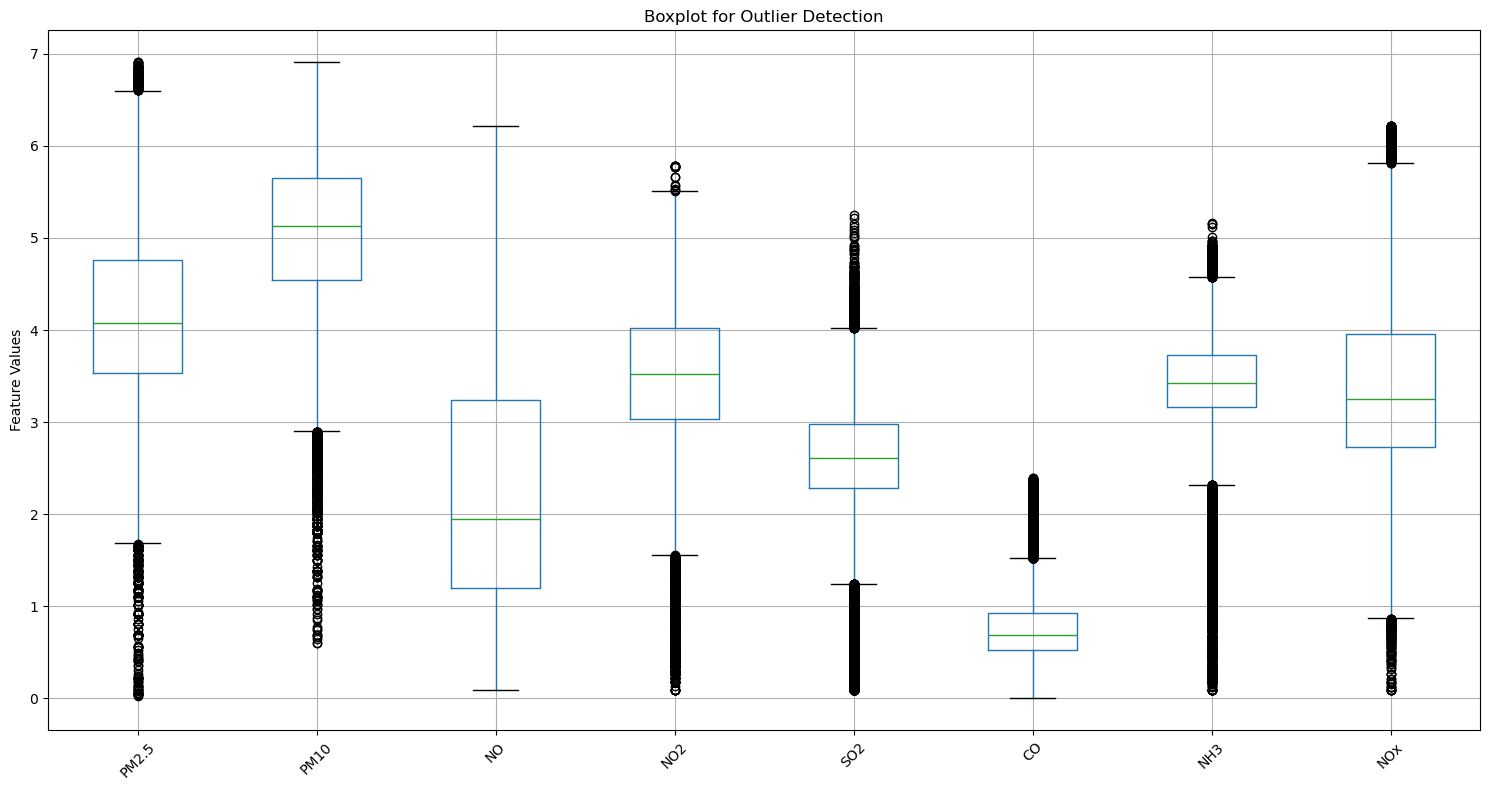

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))

df[features].boxplot()

plt.title("Boxplot for Outlier Detection")
plt.ylabel("Feature Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [40]:
print("Original dataset shape:", df.shape)

outlier_mask = pd.Series(False, index=df.index)

for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    col_outliers = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    )

    outlier_mask = outlier_mask | col_outliers

print("Total rows identified as outliers:", outlier_mask.sum())

df_clean = df[~outlier_mask].copy()

print("Dataset shape after removing outliers:", df_clean.shape)
print("Rows removed:", df.shape[0] - df_clean.shape[0])

Original dataset shape: (70227, 21)
Total rows identified as outliers: 10018
Dataset shape after removing outliers: (60209, 21)
Rows removed: 10018


In [41]:
# Impute missing values
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_imputed = imputer.fit_transform(
    df_clean[features]
)

# Scale features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_imputed)

print("Final clustering data shape:", X_scaled.shape)

Final clustering data shape: (60209, 8)


In [42]:
print("=" * 60)
print("FINAL PREPROCESSING VALIDATION")
print("=" * 60)

print("Dataset shape:", df.shape)
print("Number of features:", len(features))
print("Features:", features)

print("\nDuplicate rows:",
      df.duplicated().sum())

print("Missing values:",
      np.isnan(X_imputed).sum())

print("Infinite values:",
      np.isinf(X_imputed).sum())

print("\nScaled means:")
print(np.round(X_scaled.mean(axis=0), 3))

print("\nScaled standard deviations:")
print(np.round(X_scaled.std(axis=0), 3))

print("\nFinal X shape:",
      X_scaled.shape)

FINAL PREPROCESSING VALIDATION
Dataset shape: (70227, 21)
Number of features: 8
Features: ['PM2.5', 'PM10', 'NO', 'NO2', 'SO2', 'CO', 'NH3', 'NOx']

Duplicate rows: 0
Missing values: 0
Infinite values: 0

Scaled means:
[-0. -0.  0.  0. -0. -0. -0. -0.]

Scaled standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1.]

Final X shape: (60209, 8)


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from scipy.cluster.hierarchy import linkage, dendrogram

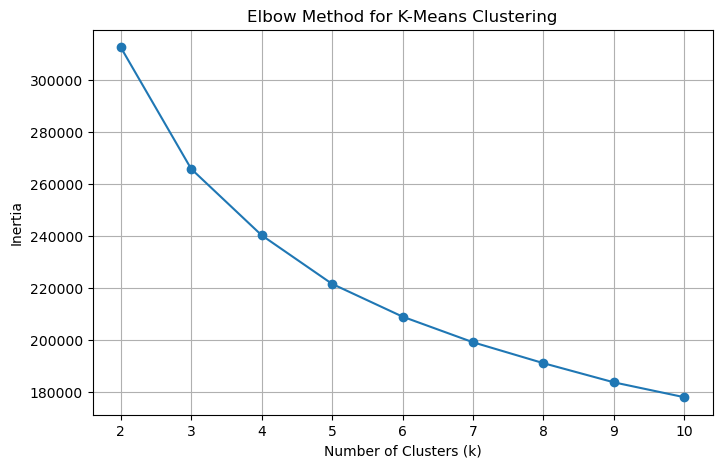

k = 2, Inertia = 312674.58
k = 3, Inertia = 265830.07
k = 4, Inertia = 240269.09
k = 5, Inertia = 221540.21
k = 6, Inertia = 208922.93
k = 7, Inertia = 199056.99
k = 8, Inertia = 190997.52
k = 9, Inertia = 183618.30
k = 10, Inertia = 177889.04


In [44]:
# ELBOW METHOD FOR K-MEANS

K_range = range(2, 11)
inertias = []

for k in K_range:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertias.append(model.inertia_)

# Plot Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means Clustering")
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

# Display values
for k, inertia in zip(K_range, inertias):
    print(f"k = {k}, Inertia = {inertia:.2f}")

In [45]:
# FINAL K-MEANS MODEL

optimal_k = 4  # Change this if your Elbow curve suggests another k

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

df_clean = df_clean.copy()
df_clean["KMeans_Cluster"] = kmeans_labels

print("K-Means completed successfully!")
print("\nCluster sizes:")
print(df_clean["KMeans_Cluster"].value_counts().sort_index())

K-Means completed successfully!

Cluster sizes:
KMeans_Cluster
0    18920
1    11977
2    12243
3    17069
Name: count, dtype: int64


In [47]:
silhouette = silhouette_score(X_scaled, kmeans_labels)

davies_bouldin = davies_bouldin_score(
    X_scaled, kmeans_labels
)

calinski_harabasz = calinski_harabasz_score(
    X_scaled, kmeans_labels
)

print("K-MEANS EVALUATION")
print("-" * 35)
print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Index:", round(davies_bouldin, 4))
print("Calinski-Harabasz Index:", round(calinski_harabasz, 2))

K-MEANS EVALUATION
-----------------------------------
Silhouette Score: 0.1947
Davies-Bouldin Index: 1.5751
Calinski-Harabasz Index: 20163.08


In [48]:
# SAMPLE DATA FOR HIERARCHICAL CLUSTERING

from sklearn.utils import resample

sample_size = min(1000, len(X_scaled))

rng = np.random.RandomState(42)

sample_indices = rng.choice(
    len(X_scaled),
    size=sample_size,
    replace=False
)

X_hier = X_scaled[sample_indices]

print("Original observations:", len(X_scaled))
print("Hierarchical sample size:", len(X_hier))
print("Number of features:", X_hier.shape[1])

Original observations: 60209
Hierarchical sample size: 1000
Number of features: 8


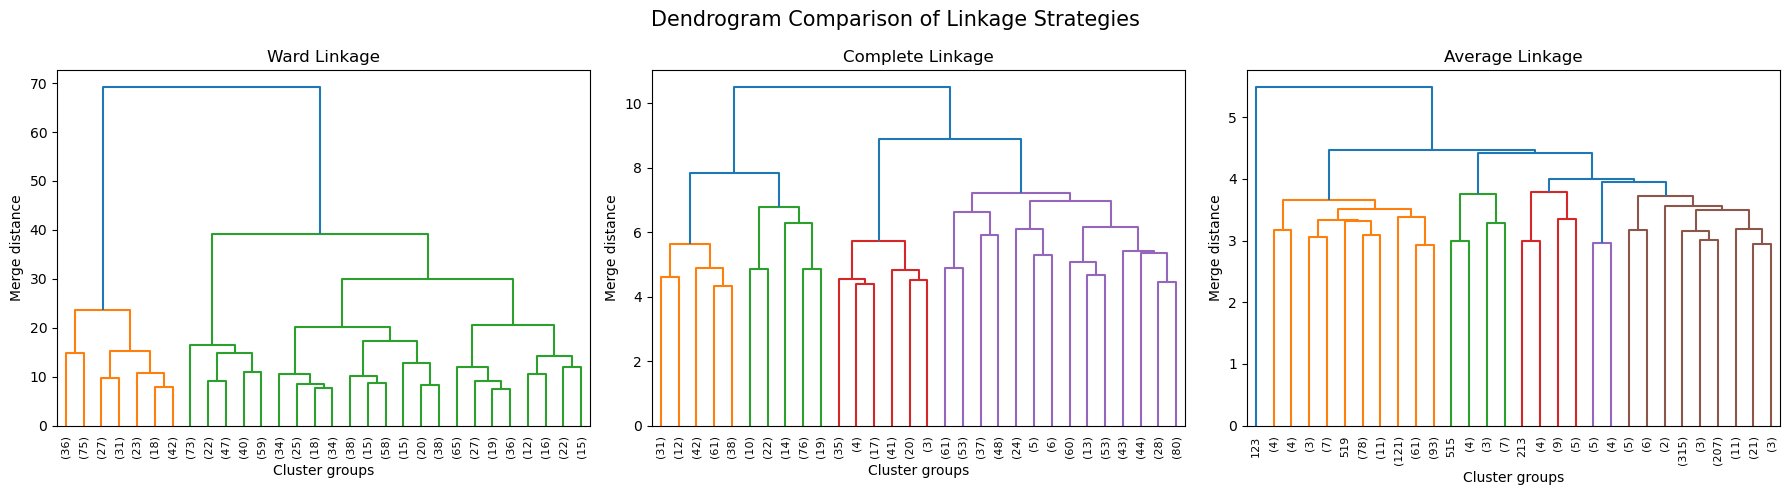

In [49]:
# DENDROGRAM COMPARISON

linkage_methods = ["ward", "complete", "average"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, method in zip(axes, linkage_methods):

    Z = linkage(
        X_hier,
        method=method,
        metric="euclidean"
    )

    dendrogram(
        Z,
        truncate_mode="lastp",
        p=30,
        leaf_rotation=90,
        leaf_font_size=8,
        ax=ax
    )

    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Cluster groups")
    ax.set_ylabel("Merge distance")

plt.suptitle(
    "Dendrogram Comparison of Linkage Strategies",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [50]:
# AGGLOMERATIVE CLUSTERING: LINKAGE COMPARISON

linkage_results = []

for method in ["ward", "complete", "average"]:

    model = AgglomerativeClustering(
        n_clusters=optimal_k,
        linkage=method,
        metric="euclidean"
    )

    labels = model.fit_predict(X_hier)

    linkage_results.append({
        "Linkage": method.capitalize(),
        "Silhouette Score": silhouette_score(
            X_hier, labels
        ),
        "Davies-Bouldin Index": davies_bouldin_score(
            X_hier, labels
        ),
        "Calinski-Harabasz Score": calinski_harabasz_score(
            X_hier, labels
        )
    })

linkage_comparison = pd.DataFrame(linkage_results)

display(
    linkage_comparison.round(4)
)

,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,Ward,0.1525,1.8538,273.7958
1,Complete,0.0951,1.7774,213.7773
2,Average,0.2410,1.1347,179.4772


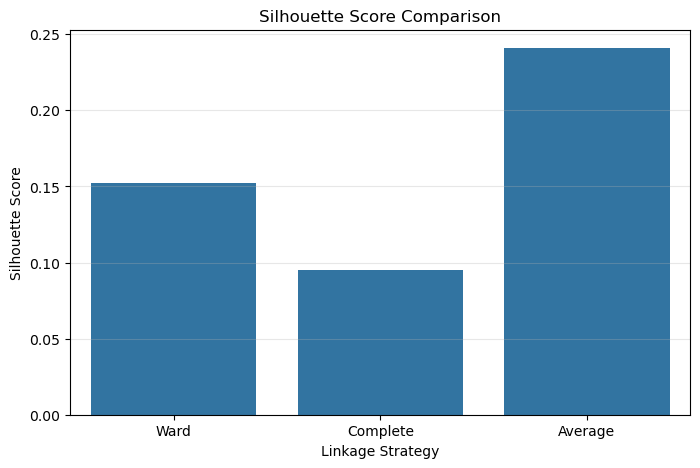

In [51]:
# COMPARE SILHOUETTE SCORES

plt.figure(figsize=(8, 5))

sns.barplot(
    data=linkage_comparison,
    x="Linkage",
    y="Silhouette Score"
)

plt.title("Silhouette Score Comparison")
plt.xlabel("Linkage Strategy")
plt.ylabel("Silhouette Score")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [52]:
# FINAL HIERARCHICAL MODEL ON THE SAMPLE

best_linkage = "ward"

hierarchical_model = AgglomerativeClustering(
    n_clusters=optimal_k,
    linkage=best_linkage,
    metric="euclidean"
)

hierarchical_labels = hierarchical_model.fit_predict(X_hier)

print("Agglomerative clustering completed!")
print("Selected linkage:", best_linkage)
print("Number of clusters:", len(np.unique(hierarchical_labels)))

print("\nCluster sizes:")
print(
    pd.Series(hierarchical_labels)
    .value_counts()
    .sort_index()
)

Agglomerative clustering completed!
Selected linkage: ward
Number of clusters: 4

Cluster sizes:
0    252
1    212
2    241
3    295
Name: count, dtype: int64


In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print("Data shape:", X_scaled.shape)

Data shape: (60209, 8)


In [54]:
np.random.seed(42)

sample_size = min(1000, len(X_scaled))

sample_indices = np.random.choice(
    len(X_scaled),
    size=sample_size,
    replace=False
)

X_hier = X_scaled[sample_indices]

print("Sample size:", X_hier.shape[0])

Sample size: 1000


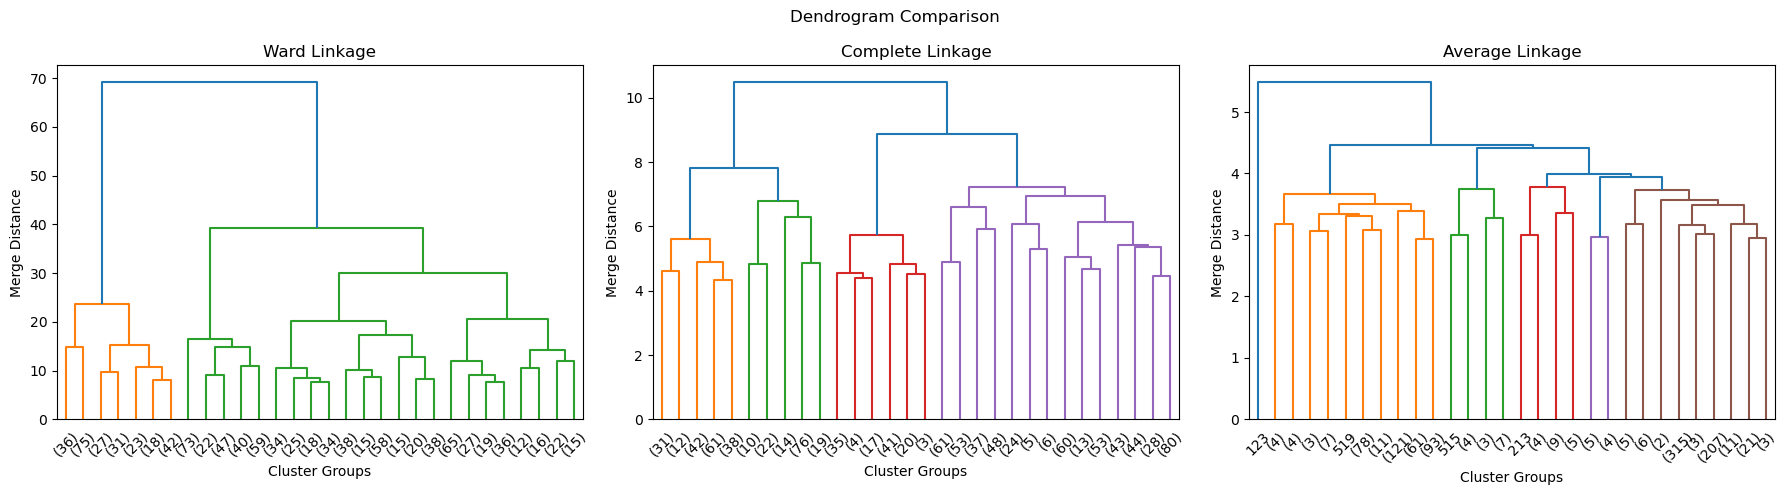

In [55]:
linkage_methods = ["ward", "complete", "average"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, method in zip(axes, linkage_methods):

    Z = linkage(
        X_hier,
        method=method,
        metric="euclidean"
    )

    dendrogram(
        Z,
        truncate_mode="lastp",
        p=30,
        ax=ax
    )

    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Cluster Groups")
    ax.set_ylabel("Merge Distance")

plt.suptitle("Dendrogram Comparison")
plt.tight_layout()
plt.show()

In [56]:
linkage_results = []

for method in ["ward", "complete", "average"]:

    model = AgglomerativeClustering(
        n_clusters=optimal_k,
        linkage=method,
        metric="euclidean"
    )

    labels = model.fit_predict(X_hier)

    linkage_results.append({
        "Linkage": method.capitalize(),
        "Silhouette Score": silhouette_score(
            X_hier, labels
        ),
        "Davies-Bouldin Index": davies_bouldin_score(
            X_hier, labels
        ),
        "Calinski-Harabasz Score": calinski_harabasz_score(
            X_hier, labels
        )
    })

linkage_comparison = pd.DataFrame(linkage_results)

display(linkage_comparison.round(4))

,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,Ward,0.1525,1.8538,273.7958
1,Complete,0.0951,1.7774,213.7773
2,Average,0.2410,1.1347,179.4772


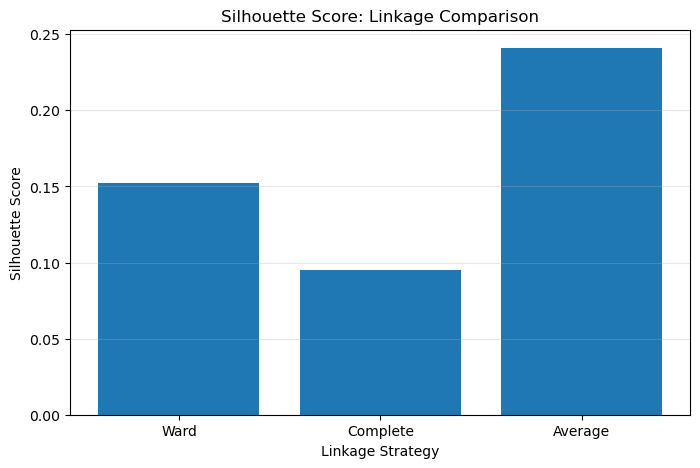

In [57]:
plt.figure(figsize=(8, 5))

plt.bar(
    linkage_comparison["Linkage"],
    linkage_comparison["Silhouette Score"]
)

plt.title("Silhouette Score: Linkage Comparison")
plt.xlabel("Linkage Strategy")
plt.ylabel("Silhouette Score")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [59]:
import os
os.environ["OMP_NUM_THREADS"] = "4"

In [60]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Use the same sample for both algorithms
X_array = np.asarray(X_scaled)

rng = np.random.RandomState(42)
sample_size = min(1000, len(X_array))
sample_indices = rng.choice(
    len(X_array), size=sample_size, replace=False
)
X_eval = X_array[sample_indices]

# Use the optimal K selected from your Elbow curve
k = optimal_k if "optimal_k" in globals() else 4

# Algorithm 1: K-Means
kmeans_eval = KMeans(
    n_clusters=k, random_state=42, n_init=10
)
kmeans_labels_eval = kmeans_eval.fit_predict(X_eval)

# Algorithm 2: Hierarchical Clustering
hierarchical_eval = AgglomerativeClustering(
    n_clusters=k, linkage="ward"
)
hierarchical_labels_eval = hierarchical_eval.fit_predict(X_eval)

print("Sample size:", len(X_eval))
print("Number of clusters:", k)
print("K-Means cluster labels:", np.unique(kmeans_labels_eval))
print("Hierarchical cluster labels:", np.unique(hierarchical_labels_eval))

C:\Users\Admin\anaconda3\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


Sample size: 1000
Number of clusters: 4
K-Means cluster labels: [0 1 2 3]
Hierarchical cluster labels: [0 1 2 3]


In [61]:
results = []

algorithms = {
    "K-Means": kmeans_labels_eval,
    "Hierarchical": hierarchical_labels_eval
}

for name, labels in algorithms.items():
    results.append({
        "Algorithm": name,
        "Silhouette Score": silhouette_score(X_eval, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_eval, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(
            X_eval, labels
        )
    })

metrics_df = pd.DataFrame(results).set_index("Algorithm")

display(metrics_df.round(4))

,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
Algorithm,,,
K-Means,0.1983,1.5952,331.8224
Hierarchical,0.1525,1.8538,273.7958


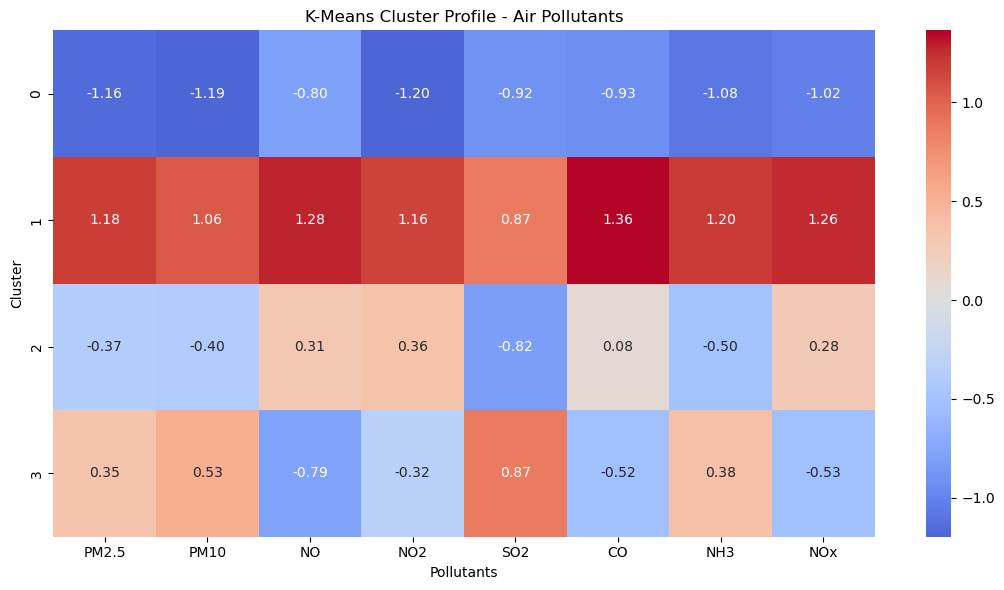

In [70]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average pollutant levels for each K-Means cluster
cluster_profile = df_clean.groupby("KMeans_Cluster")[features].mean()

# Normalize each pollutant column for easier comparison
cluster_profile_scaled = (
    cluster_profile - cluster_profile.mean()
) / cluster_profile.std()

plt.figure(figsize=(11, 6))
sns.heatmap(
    cluster_profile_scaled,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("K-Means Cluster Profile - Air Pollutants")
plt.xlabel("Pollutants")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()


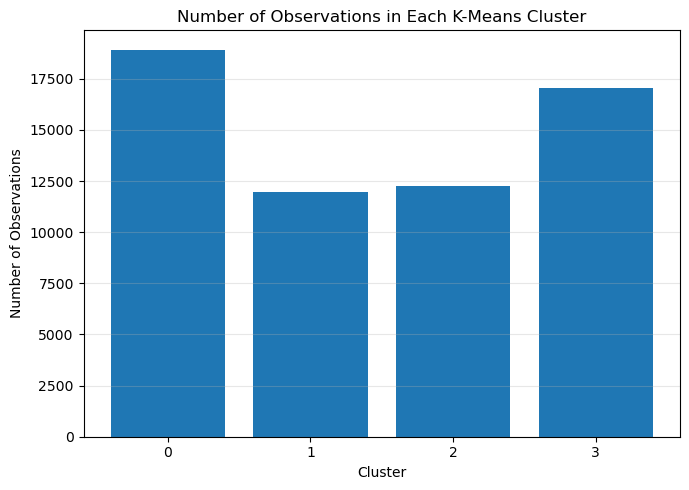

KMeans_Cluster
0    18920
1    11977
2    12243
3    17069
Name: count, dtype: int64


In [71]:

import matplotlib.pyplot as plt

cluster_counts = df_clean["KMeans_Cluster"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(cluster_counts.index.astype(str), cluster_counts.values)

plt.title("Number of Observations in Each K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Observations")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(cluster_counts)


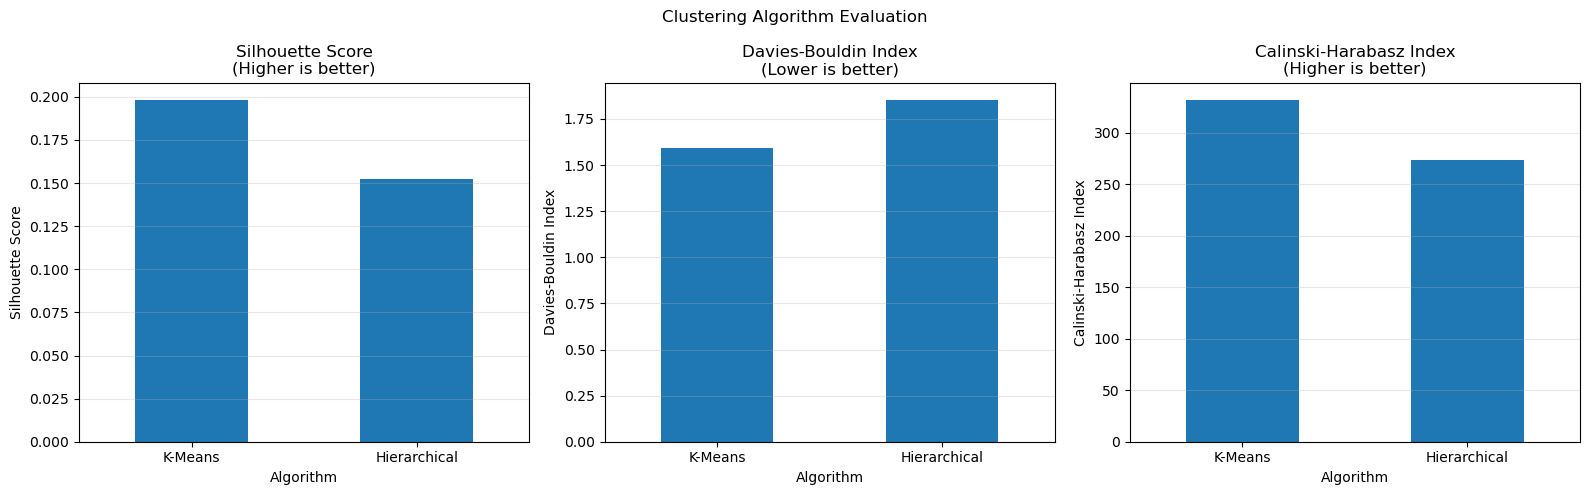

In [62]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metric_info = [
    ("Silhouette Score", "Higher is better"),
    ("Davies-Bouldin Index", "Lower is better"),
    ("Calinski-Harabasz Index", "Higher is better")
]

for ax, (metric, direction) in zip(axes, metric_info):
    metrics_df[metric].plot(
        kind="bar", ax=ax, rot=0
    )
    ax.set_title(f"{metric}\n({direction})")
    ax.set_xlabel("Algorithm")
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Clustering Algorithm Evaluation")
plt.tight_layout()
plt.show()

In [63]:
ranks = pd.DataFrame(index=metrics_df.index)

# Higher scores are better for these two metrics
ranks["Silhouette Rank"] = metrics_df[
    "Silhouette Score"
].rank(ascending=False, method="average")

ranks["Calinski-Harabasz Rank"] = metrics_df[
    "Calinski-Harabasz Index"
].rank(ascending=False, method="average")

# Lower score is better for Davies-Bouldin
ranks["Davies-Bouldin Rank"] = metrics_df[
    "Davies-Bouldin Index"
].rank(ascending=True, method="average")

ranks["Average Rank"] = ranks.mean(axis=1)

display(ranks.round(2))

best_algorithm = ranks["Average Rank"].idxmin()

print("Best overall algorithm based on average metric rank:",
      best_algorithm)

print("\nMetric-by-metric winner:")
print("Silhouette:", metrics_df["Silhouette Score"].idxmax())
print("Davies-Bouldin:", metrics_df["Davies-Bouldin Index"].idxmin())
print("Calinski-Harabasz:",
      metrics_df["Calinski-Harabasz Index"].idxmax())

,Silhouette Rank,Calinski-Harabasz Rank,Davies-Bouldin Rank,Average Rank
Algorithm,,,,
K-Means,1.0,1.0,1.0,1.0
Hierarchical,2.0,2.0,2.0,2.0


Best overall algorithm based on average metric rank: K-Means

Metric-by-metric winner:
Silhouette: K-Means
Davies-Bouldin: K-Means
Calinski-Harabasz: K-Means


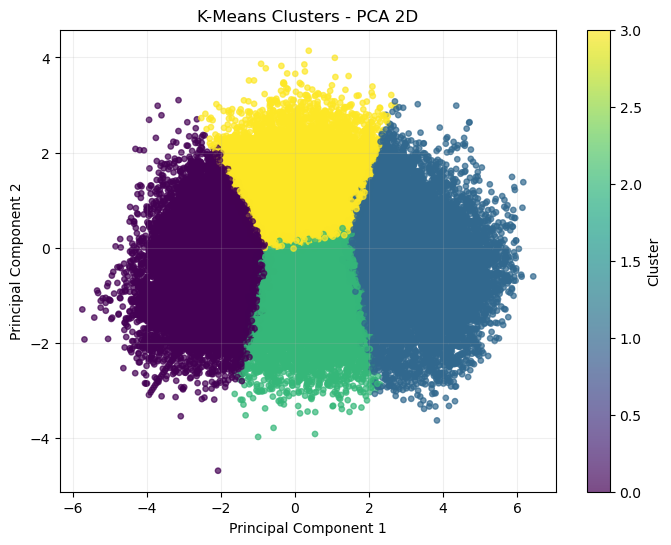

Variance explained by PCA: 67.34 %


In [64]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Get K-Means labels
kmeans_labels = df_clean["KMeans_Cluster"].to_numpy()

# Reduce features to 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Visualize clusters
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=15,
    alpha=0.7
)

plt.title("K-Means Clusters - PCA 2D")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.2)
plt.show()

print("Variance explained by PCA:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

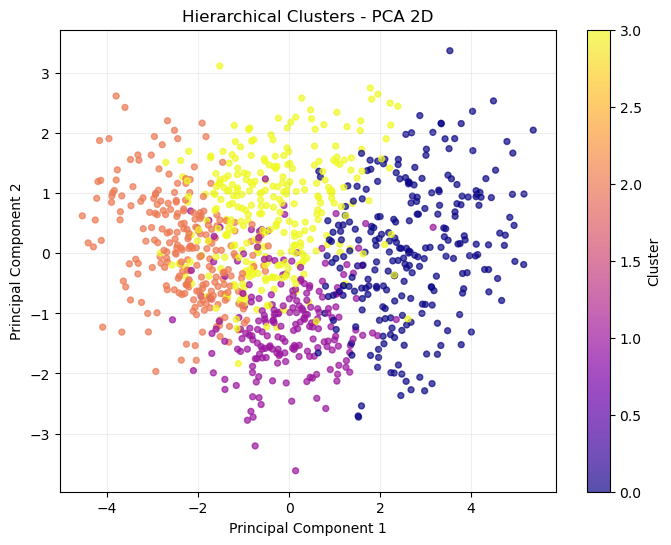

In [65]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Fit hierarchical clustering on the sample
hierarchical_model = AgglomerativeClustering(
    n_clusters=optimal_k,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(X_hier)

# Reduce sample to 2 dimensions
pca_hier = PCA(n_components=2)
X_pca_hier = pca_hier.fit_transform(X_hier)

# Visualize clusters
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca_hier[:, 0],
    X_pca_hier[:, 1],
    c=hierarchical_labels,
    cmap="plasma",
    s=18,
    alpha=0.7
)

plt.title("Hierarchical Clusters - PCA 2D")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.2)
plt.show()

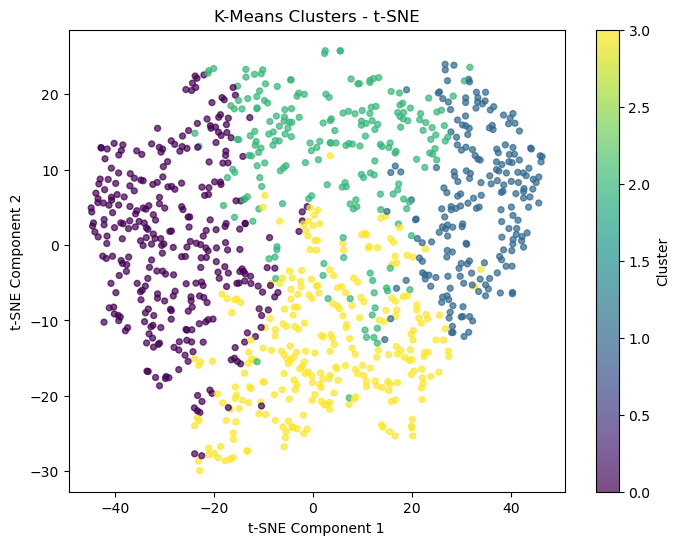

In [68]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# Select a sample to make t-SNE faster
sample_size = min(1000, len(X_scaled))

rng = np.random.RandomState(42)
tsne_indices = rng.choice(
    len(X_scaled), size=sample_size, replace=False
)

X_sample = np.asarray(X_scaled)[tsne_indices]
kmeans_sample_labels = np.asarray(kmeans_labels)[tsne_indices]

# Apply t-SNE
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=min(30, sample_size - 1),
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_sample)

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=kmeans_sample_labels, cmap="viridis",
    s=18, alpha=0.7
)
plt.title("K-Means Clusters - t-SNE")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.colorbar(label="Cluster")
plt.show()

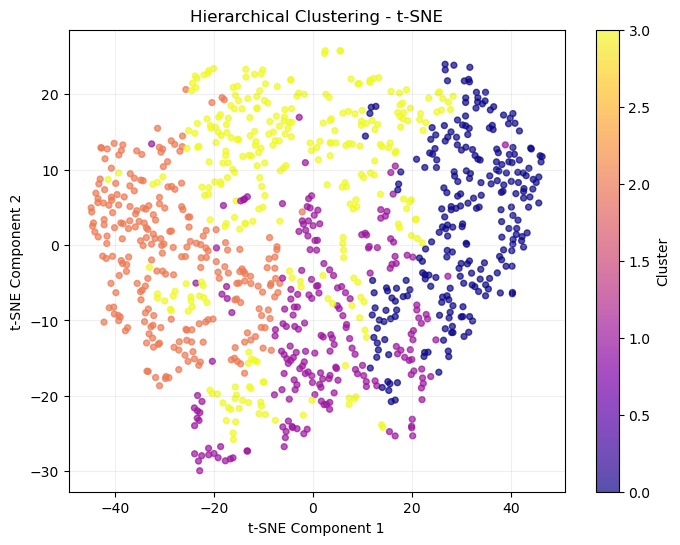

In [69]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import AgglomerativeClustering

# 1. Select a sample from your scaled dataset
sample_size = min(1000, len(X_scaled))
rng = np.random.RandomState(42)

tsne_indices = rng.choice(
    len(X_scaled), size=sample_size, replace=False
)
X_sample = np.asarray(X_scaled)[tsne_indices]

# 2. Apply t-SNE
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=min(30, sample_size - 1),
    init="pca",
    learning_rate="auto"
)
X_tsne = tsne.fit_transform(X_sample)

# 3. Fit Hierarchical Clustering
# Use the same number of clusters selected for K-Means
hierarchical_model = AgglomerativeClustering(
    n_clusters=optimal_k,
    linkage="ward"
)
hierarchical_sample_labels = hierarchical_model.fit_predict(X_sample)

# 4. Visualize clusters
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=hierarchical_sample_labels,
    cmap="plasma",
    s=18,
    alpha=0.7
)

plt.title("Hierarchical Clustering - t-SNE")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.2)
plt.show()
